In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path = "../data/raw/train_transaction.csv"
all_cols = pd.read_csv(path, nrows=0).columns
use = [c for c in all_cols if not c.startswith("V")]

df = pd.read_csv(path, usecols=use)

for c in df.select_dtypes("float64").columns:
    df[c] = df[c].astype("float32")

df.shape

(590540, 55)

In [3]:
df = df.sort_values("TransactionDT").reset_index(drop=True)
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,0.0,T,T,T,M2,F,T,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,0.0,NaN,NaN,NaN,M0,T,T,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,315.0,T,T,T,M0,F,F,F,F,F
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,111.0,NaN,NaN,NaN,M0,T,F,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df.shape)
print("Fraud rate:", df["isFraud"].mean())
print(df["TransactionDT"].agg(["min", "max"]))
print("IDs unique?", df["TransactionID"].is_unique)
df.isna().mean().sort_values(ascending=False).head(15)

(590540, 55)
Fraud rate: 0.03499000914417313
min       86400
max    15811131
Name: TransactionDT, dtype: int64
IDs unique? True


dist2            0.936284
D7               0.934099
D13              0.895093
D14              0.894695
D12              0.890410
D6               0.876068
D9               0.873123
D8               0.873123
R_emaildomain    0.767516
dist1            0.596524
M5               0.593494
M7               0.586353
M9               0.586331
M8               0.586331
D5               0.524674
dtype: float64

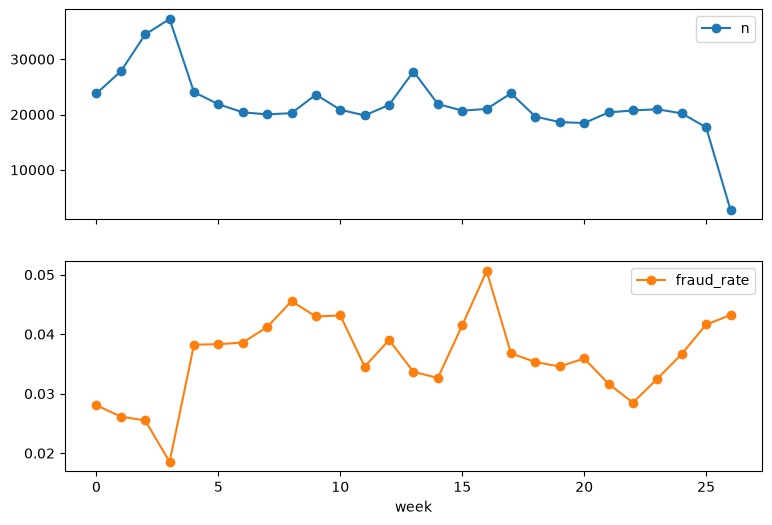

In [5]:
df["day"] = df["TransactionDT"] / 86400
df["week"] = (df["day"] // 7).astype(int)

weekly = df.groupby("week").agg(n=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
weekly.plot(subplots=True, figsize=(9, 6), marker="o")
plt.show()

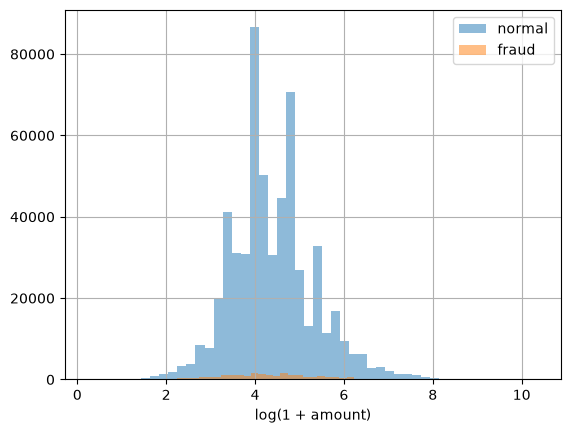

In [6]:
np.log1p(df.loc[df.isFraud == 0, "TransactionAmt"]).hist(bins=50, alpha=.5, label="normal")
np.log1p(df.loc[df.isFraud == 1, "TransactionAmt"]).hist(bins=50, alpha=.5, label="fraud")
plt.legend()
plt.xlabel("log(1 + amount)")
plt.show()

In [7]:
df.groupby("ProductCD")["isFraud"].mean()

ProductCD
C    0.116873
H    0.047662
R    0.037826
S    0.058996
W    0.020399
Name: isFraud, dtype: float64

Fraud rate is about 3.5% overall, so accuracy would be misleading. Weekly fraud rate is not stable and peaks around week 15, which falls inside the planned production window, so natural variation will appear in monitoring. Transaction amounts of fraud and normal payments overlap heavily, so amount alone is a weak signal. Fraud rate varies a lot by product code: C is about 11.7% versus W at about 2.0%, so ProductCD is a strong feature.

In [8]:
df["split"] = "unused"
df.loc[df.day < 60, "split"] = "train"
df.loc[(df.day >= 60) & (df.day < 90), "split"] = "val"
df.loc[(df.day >= 90) & (df.day < 174), "split"] = "prod"

df["batch"] = -1
m = df.split == "prod"
df.loc[m, "batch"] = ((df.loc[m, "day"] - 90) // 7).astype(int)

In [9]:
tr, va, pr = (df[df.split == s] for s in ["train", "val", "prod"])
assert tr.TransactionDT.max() < va.TransactionDT.min()
assert va.TransactionDT.max() < pr.TransactionDT.min()

print(df.groupby("split").agg(rows=("isFraud", "size"), fraud_rate=("isFraud", "mean")))
print(df[df.split == "prod"].groupby("batch").size())

          rows  fraud_rate
split                     
prod    254694    0.035929
train   220806    0.031113
unused   23272    0.040478
val      91768    0.040319
batch
0     28021
1     21888
2     20635
3     21004
4     23536
5     20337
6     18613
7     18239
8     20263
9     20967
10    20802
11    20389
dtype: int64


In [10]:
df.to_parquet("../data/processed/full.parquet", index=False)